## Descriptive Statistics in Petrophysics for Python & AI Beginners

#### Keith R. Holdaway FGS

### Descriptive statistics help summarize key characteristics of well log data. 

### This guide covers fundamental statistical concepts with Python examples.

#### Keith R. Holdaway FGS

#### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#### Generate Synthetic Petrophysical Data

In [2]:
np.random.seed(42)
n_samples = 1000

# Synthetic well log data
data = {
    "Depth": np.arange(1, n_samples + 1),
    "Porosity": np.random.normal(0.15, 0.05, n_samples).clip(0),  # Fraction (0-1)
    "Permeability": np.random.lognormal(mean=1.5, sigma=0.7, size=n_samples),  # mD
    "GammaRay": np.random.gamma(shape=2, scale=30, size=n_samples),  # API units
    "Lithology": np.random.choice(["Sandstone", "Shale", "Limestone"], size=n_samples)
}

df = pd.DataFrame(data)

#### Compute Basic Statistics

In [3]:
print("=== Basic Statistics ===")
print(df[["Porosity", "Permeability", "GammaRay"]].describe())

print("\n=== Lithology Distribution ===")
print(df["Lithology"].value_counts())

print("\n=== Skewness & Kurtosis ===")
print("Porosity Skewness:", stats.skew(df["Porosity"]))
print("Permeability Kurtosis:", stats.kurtosis(df["Permeability"]))

=== Basic Statistics ===
          Porosity  Permeability     GammaRay
count  1000.000000   1000.000000  1000.000000
mean      0.150979      5.992810    60.994072
std       0.048922      4.634518    44.155436
min       0.000000      0.572197     0.775815
25%       0.117620      2.931842    29.260272
50%       0.151265      4.684009    51.572493
75%       0.182397      7.464950    79.955419
max       0.342637     41.895369   408.306981

=== Lithology Distribution ===
Lithology
Shale        352
Sandstone    336
Limestone    312
Name: count, dtype: int64

=== Skewness & Kurtosis ===
Porosity Skewness: 0.12397201575609007
Permeability Kurtosis: 9.537155266565485


#### Visualizations

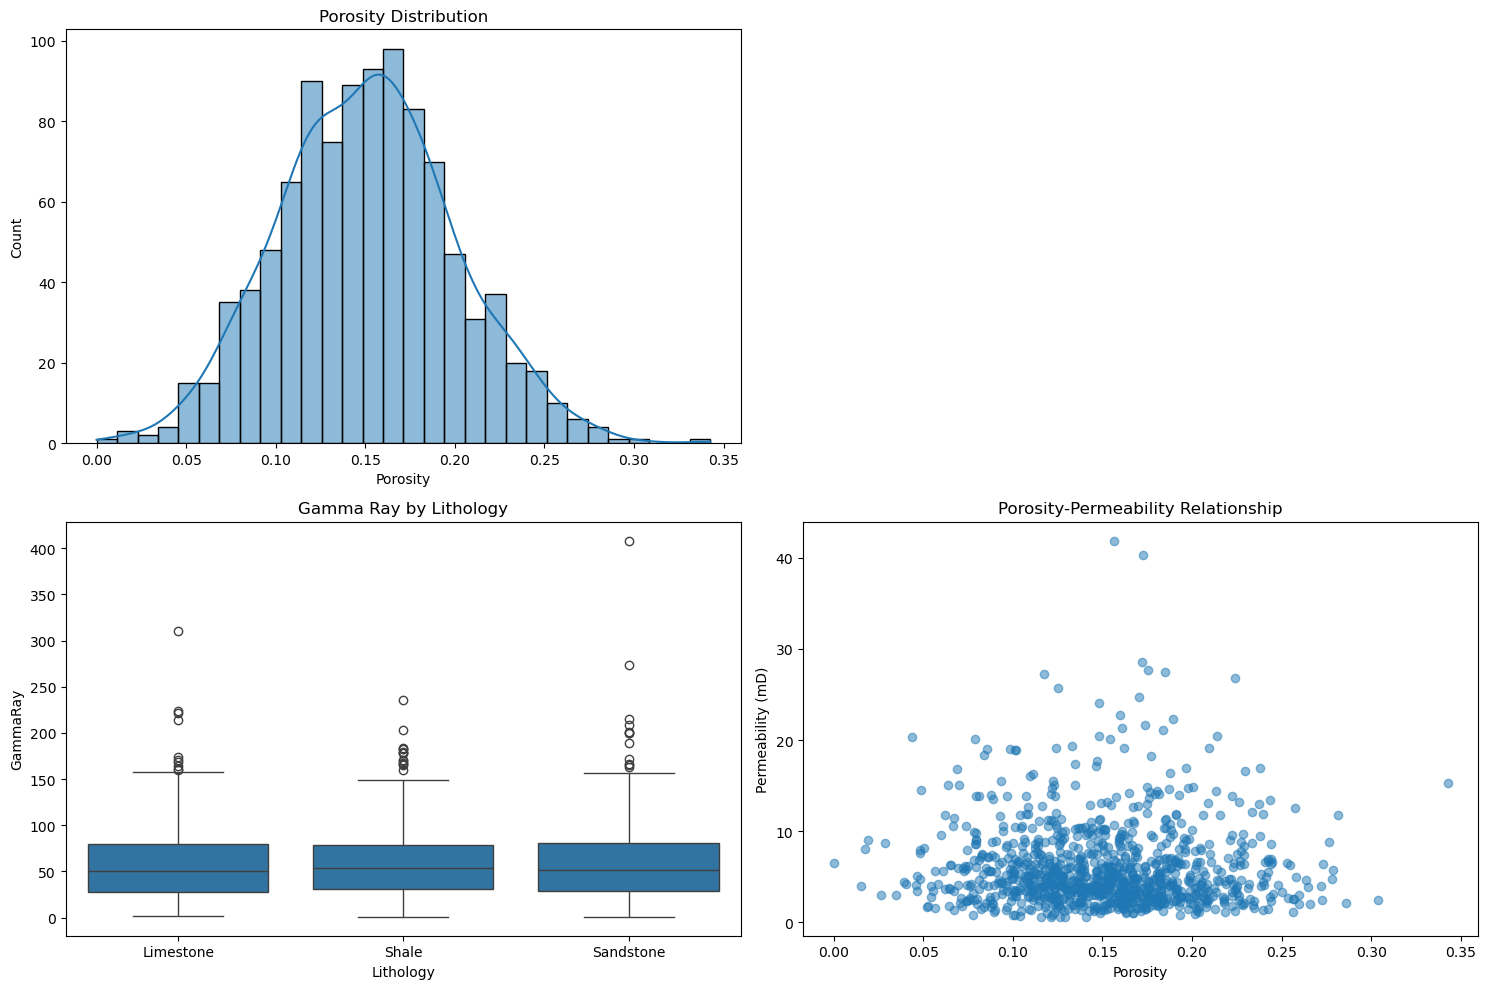

In [4]:
plt.figure(figsize=(15, 10))

# Histograms
plt.subplot(2, 2, 1)
sns.histplot(df["Porosity"], kde=True, bins=30)
plt.title("Porosity Distribution")

# Boxplot by lithology
plt.subplot(2, 2, 3)
sns.boxplot(data=df, x="Lithology", y="GammaRay")
plt.title("Gamma Ray by Lithology")

# Scatter plot (Porosity vs Permeability)
plt.subplot(2, 2, 4)
plt.scatter(df["Porosity"], df["Permeability"], alpha=0.5)
plt.xlabel("Porosity")
plt.ylabel("Permeability (mD)")
plt.title("Porosity-Permeability Relationship")

plt.tight_layout()
plt.show()

Key Insights:

Porosity is ~normally distributed.

Gamma Ray helps distinguish lithologies (Shale has higher GR).

#### Understanding Kurtosis and Skewness in Petrophysics with Python

Kurtosis and skewness are essential statistical measures that help petrophysicists understand the distribution of well log data. These metrics provide insights into reservoir heterogeneity, fluid distributions, and rock properties.

#### Skewness in Petrophysics
Definition: Measures asymmetry in data distribution.

Applications:
Identifying lithology trends (e.g., shale vs. sandstone)

Detecting fluid contacts (oil-water transition zones)

Evaluating log responses (e.g., gamma ray in shales is right-skewed)

Skewness: -0.02
Left-skewed (tail extends to lower values)


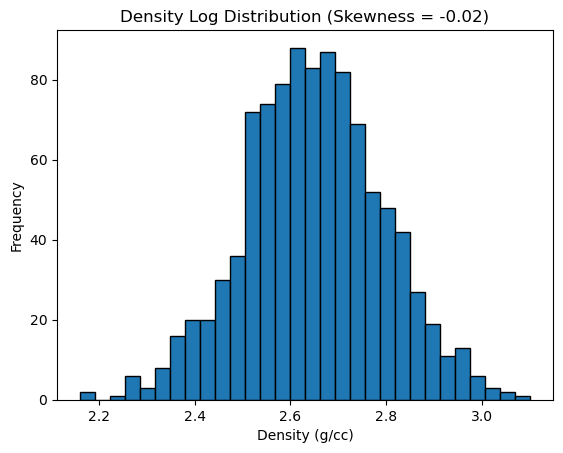

In [5]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Synthetic density log (g/cc)
density_log = np.random.normal(2.65, 0.15, 1000)  # Sandstone-dominated

# Compute skewness
skewness = stats.skew(density_log)
print(f"Skewness: {skewness:.2f}")

# Interpretation
if skewness > 0:
    print("Right-skewed (tail extends to higher values)")
elif skewness < 0:
    print("Left-skewed (tail extends to lower values)")
else:
    print("Symmetric distribution")

# Visualization
plt.hist(density_log, bins=30, edgecolor='k')
plt.title(f"Density Log Distribution (Skewness = {skewness:.2f})")
plt.xlabel("Density (g/cc)")
plt.ylabel("Frequency")
plt.show()

#### Output:
Skewness: (Nearly symmetric, typical for clean sandstone)

#### Kurtosis in Petrophysics
Definition: Measures "tailedness" (outlier frequency).

Applications:
Detecting fractures/vugs (high kurtosis → heavy tails)

Identifying thin beds (affects log resolution)

Quality control (outliers may indicate bad log data)

Kurtosis: 4.67
Leptokurtic (heavy tails, more outliers)


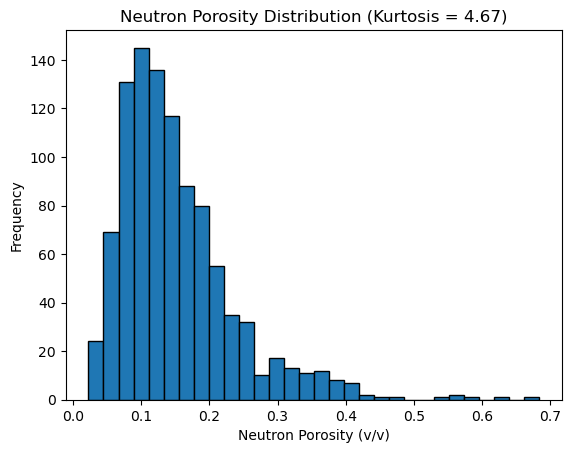

In [6]:
# Synthetic neutron porosity log (fractional)
neutron_porosity = np.random.lognormal(mean=-2, sigma=0.5, size=1000)

# Compute kurtosis (Fisher's definition, normal=0)
kurtosis = stats.kurtosis(neutron_porosity)
print(f"Kurtosis: {kurtosis:.2f}")

# Interpretation
if kurtosis > 0:
    print("Leptokurtic (heavy tails, more outliers)")
elif kurtosis < 0:
    print("Platykurtic (light tails, fewer outliers)")
else:
    print("Mesokurtic (normal distribution)")

# Visualization
plt.hist(neutron_porosity, bins=30, edgecolor='k')
plt.title(f"Neutron Porosity Distribution (Kurtosis = {kurtosis:.2f})")
plt.xlabel("Neutron Porosity (v/v)")
plt.ylabel("Frequency")
plt.show()

#### Output:
Kurtosis: (Leptokurtic, common in heterogeneous formations)

## Practical Workflow for Petrophysicists

### Load Well Log Data

In [7]:
import pandas as pd

# Example: Loading CSV file
df = pd.read_csv("synthetic_well_logs.csv")
gr = df["GR"]      # Gamma Ray (API)
phid = df["NPHI"]  # Neutron Porosity (v/v)

### Analyze Distributions

GR Skewness: -0.09
NPHI Kurtosis: -1.24


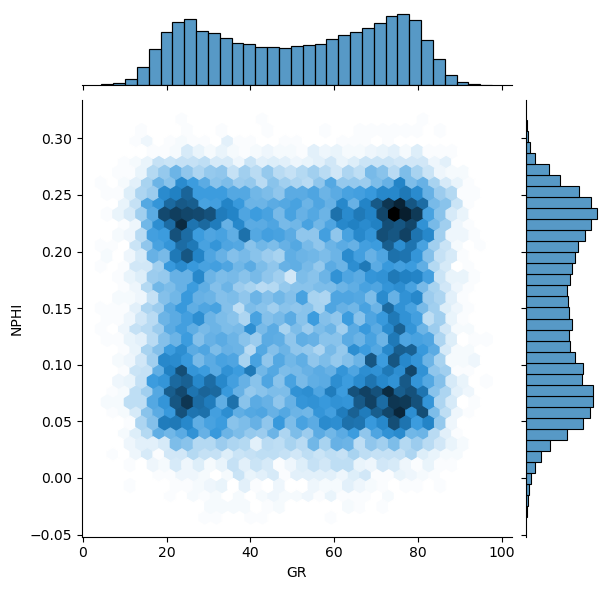

In [8]:
print(f"GR Skewness: {stats.skew(gr):.2f}")
print(f"NPHI Kurtosis: {stats.kurtosis(phid):.2f}")

# Multi-log distribution plot
sns.jointplot(x=gr, y=phid, kind="hex")
plt.show()

#### Metric	Typical Values in Petrophysics	Implications
#### Skewness > 0	Common in gamma ray (shale has high GR)	Indicates shale presence
#### Skewness < 0	Rare but seen in resistivity in oil zones	Possible hydrocarbon effect
#### High Kurtosis	Fractured carbonates or vuggy zones	High permeability pathways
#### Low Kurtosis	Homogeneous sandstones	Uniform reservoir quality

### AI Integration
#### Machine learning models benefit from skewness/kurtosis analysis:

Preprocessing: Log normalization (e.g., Box-Cox transform for skewed data)

Feature engineering: Use kurtosis to flag potential fractures

Clustering: Distinguish lithofacies based on distribution shapes

In [9]:
from sklearn.preprocessing import PowerTransformer

# Fix skewness for machine learning
pt = PowerTransformer(method='yeo-johnson')
gr_normalized = pt.fit_transform(gr.values.reshape(-1, 1))

## Key Takeaways
### Skewness → Detects asymmetry in fluid contacts or lithology changes.

### Kurtosis → Identifies outliers (fractures/vugs) or thin-bed effects.

Python Tools → scipy.stats, seaborn, and pandas streamline analysis.

AI Applications → Improved data preprocessing and feature selection.

By leveraging these metrics, petrophysicists can better characterize reservoirs and improve subsurface models!

#### AI Applications in Petrophysics

Clustering (K-Means, DBSCAN): Lithology prediction from logs.

Regression (Random Forest, XGBoost): Permeability prediction.

Neural Networks: Log synthesis (e.g., predicting sonic logs from GR/resistivity).

In [12]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

df = pd.read_csv("petrophysical_data.csv")

# Remove rows with any NaN values
df_clean = df.dropna()

# Use the CLEANED dataframe to define X and y
X = df_clean[["NPHI", "PHIT", "GammaRay"]]
y = df_clean["Lithology"]

# Now you can train your model
model = RandomForestClassifier()
model.fit(X, y)
print("Feature Importance:", model.feature_importances_)

Feature Importance: [0.33969567 0.33482609 0.32547824]


#### Mean/Median/Mode → Identify central trends.
#### Variance/Skewness → Understand heterogeneity.
#### Visualizations → Detect patterns & outliers.
#### AI Integration → Enhances log analysis & predictions.

### More Realistic Petroleum Engineering Example to generate a proper log-normal distribution for permeability.

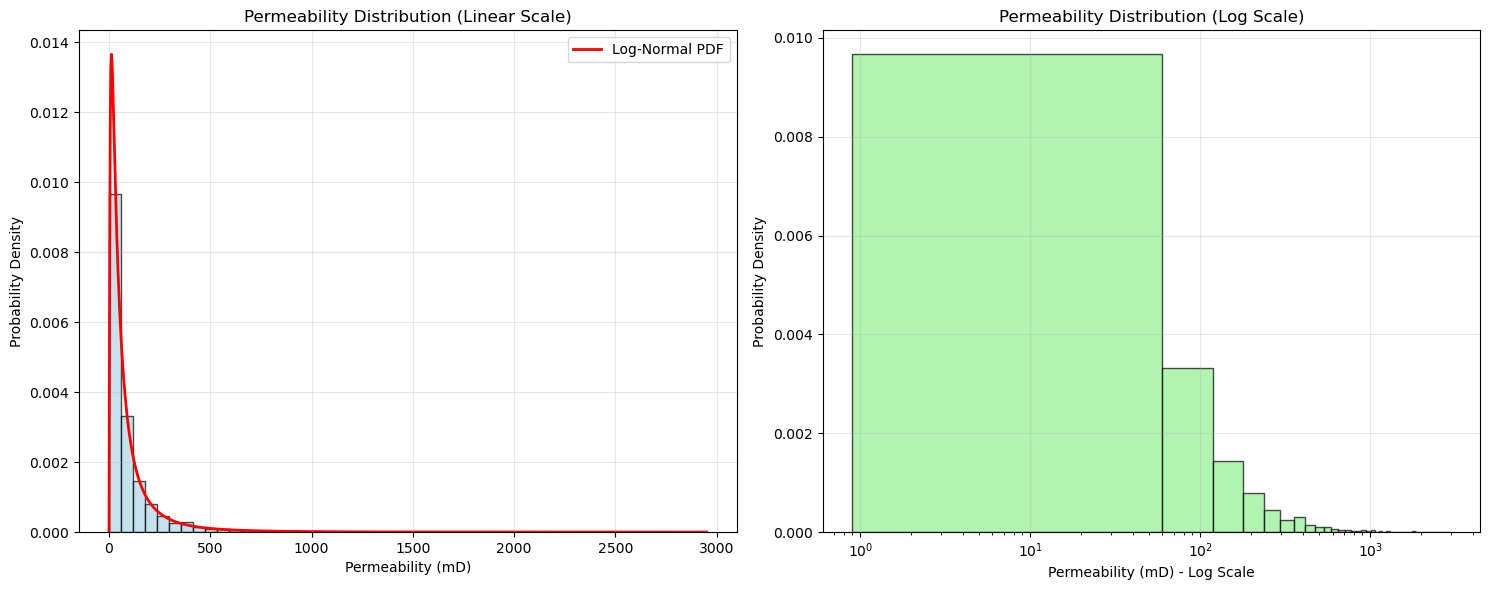

=== PERMEABILITY STATISTICS ===
Geometric mean: 49.02 mD
Arithmetic mean: 104.56 mD
Median: 49.39 mD
P10: 9.90 mD
P50: 49.39 mD
P90: 237.74 mD


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Typical permeability ranges for different rock types (in mD)
# These are realistic values for petroleum engineering
rock_types = {
    'Shale': (0.0001, 0.01),
    'Tight Sandstone': (0.01, 0.1),
    'Sandstone': (1, 1000),
    'Carbonate': (0.1, 100),
    'Fractured Reservoir': (10, 10000)
}

# Generate log-normal permeability for sandstone (most common reservoir rock)
mu_log = np.log(50)  # Median around 50 mD
sigma_log = 1.2      # Moderate variability
n_samples = 2000

permeability = np.random.lognormal(mean=mu_log, sigma=sigma_log, size=n_samples)

# Create the plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Linear scale plot
ax1.hist(permeability, bins=50, density=True, alpha=0.7, color='lightblue', edgecolor='black')
x = np.linspace(0, max(permeability), 1000)
pdf = stats.lognorm.pdf(x, s=sigma_log, scale=np.exp(mu_log))
ax1.plot(x, pdf, 'r-', lw=2, label='Log-Normal PDF')
ax1.set_xlabel('Permeability (mD)')
ax1.set_ylabel('Probability Density')
ax1.set_title('Permeability Distribution (Linear Scale)')
ax1.legend()
ax1.grid(alpha=0.3)

# Log scale plot (often more informative for permeability)
ax2.hist(permeability, bins=50, density=True, alpha=0.7, color='lightgreen', edgecolor='black')
ax2.set_xscale('log')
ax2.set_xlabel('Permeability (mD) - Log Scale')
ax2.set_ylabel('Probability Density')
ax2.set_title('Permeability Distribution (Log Scale)')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Statistical summary
print("=== PERMEABILITY STATISTICS ===")
print(f"Geometric mean: {np.exp(np.mean(np.log(permeability))):.2f} mD")
print(f"Arithmetic mean: {np.mean(permeability):.2f} mD")
print(f"Median: {np.median(permeability):.2f} mD")
print(f"P10: {np.percentile(permeability, 10):.2f} mD")
print(f"P50: {np.percentile(permeability, 50):.2f} mD")
print(f"P90: {np.percentile(permeability, 90):.2f} mD")

Example 1: Typical Sandstone Reservoir (μ_log=3.0, σ_log=1.0)


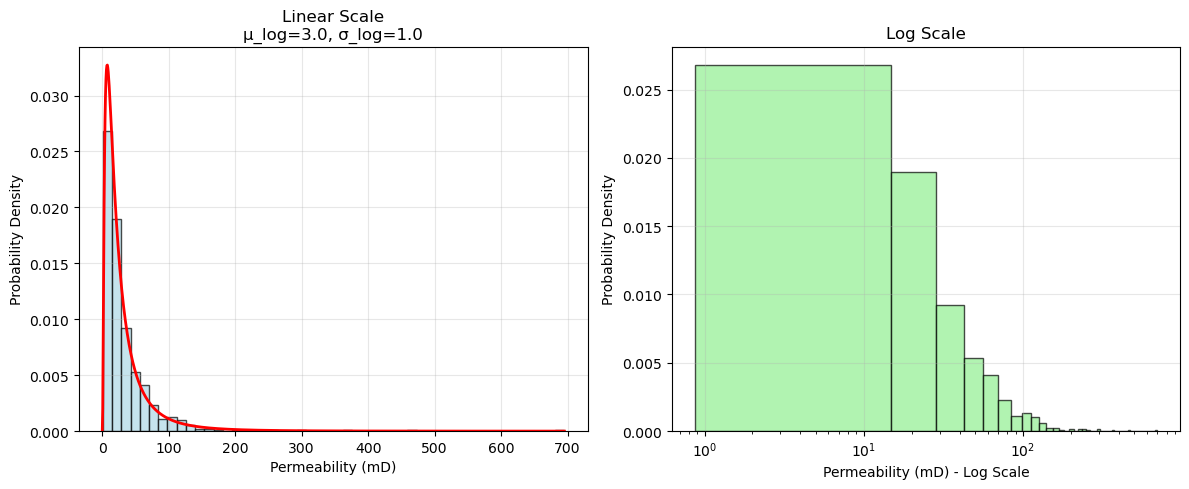

=== PERMEABILITY STATISTICS ===
Geometric mean: 20.23 mD
Arithmetic mean: 33.33 mD
Median: 19.65 mD
P10: 5.61 mD
P50: 19.65 mD
P90: 71.79 mD
Standard deviation: 44.63 mD


Example 2: Tight Sandstone (μ_log=0.0, σ_log=1.2)


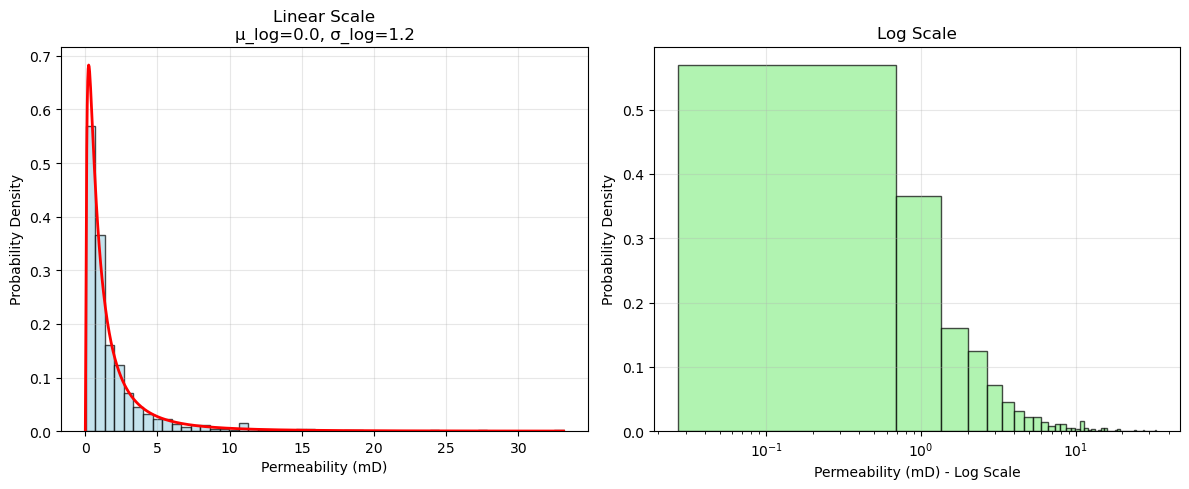

=== PERMEABILITY STATISTICS ===
Geometric mean: 0.98 mD
Arithmetic mean: 1.95 mD
Median: 0.96 mD
P10: 0.22 mD
P50: 0.96 mD
P90: 4.44 mD
Standard deviation: 2.96 mD


Example 3: Highly Permeable Sandstone (μ_log=4.0, σ_log=0.8)


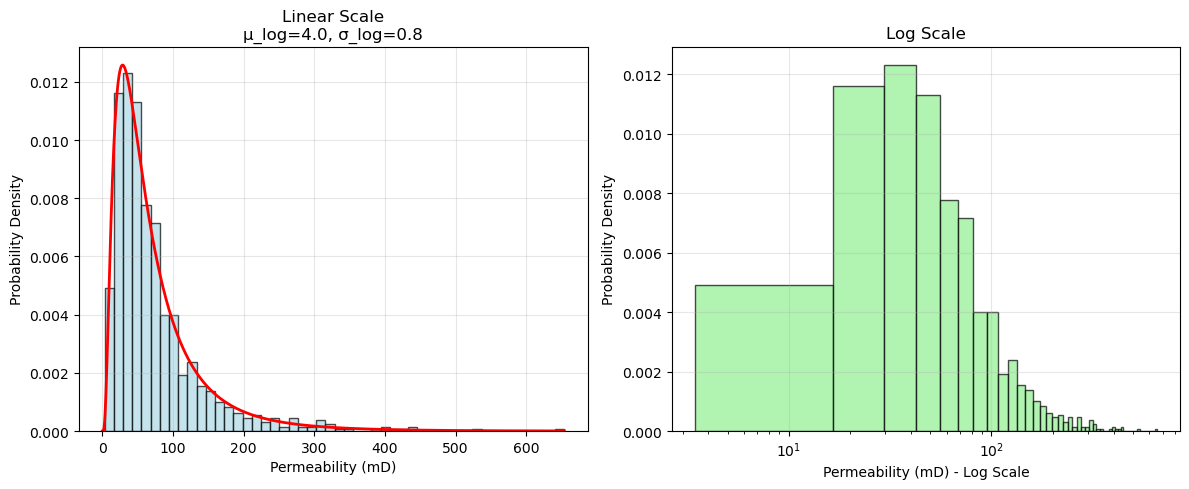

=== PERMEABILITY STATISTICS ===
Geometric mean: 53.60 mD
Arithmetic mean: 73.57 mD
Median: 53.29 mD
P10: 19.53 mD
P50: 53.29 mD
P90: 148.99 mD
Standard deviation: 68.26 mD


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

def plot_permeability_distribution(mu_log=2.0, sigma_log=1.0, n_samples=1000):
    """Plot log-normal permeability distribution with different parameters"""
    
    # Generate log-normal permeability values
    permeability = np.random.lognormal(mean=mu_log, sigma=sigma_log, size=n_samples)
    
    plt.figure(figsize=(12, 5))
    
    # Linear scale
    plt.subplot(1, 2, 1)
    plt.hist(permeability, bins=50, density=True, alpha=0.7, color='lightblue', edgecolor='black')
    x = np.linspace(0, max(permeability), 1000)
    pdf = stats.lognorm.pdf(x, s=sigma_log, scale=np.exp(mu_log))
    plt.plot(x, pdf, 'r-', lw=2)
    plt.xlabel('Permeability (mD)')
    plt.ylabel('Probability Density')
    plt.title(f'Linear Scale\nμ_log={mu_log}, σ_log={sigma_log}')
    plt.grid(alpha=0.3)
    
    # Log scale
    plt.subplot(1, 2, 2)
    plt.hist(permeability, bins=50, density=True, alpha=0.7, color='lightgreen', edgecolor='black')
    plt.xscale('log')
    plt.xlabel('Permeability (mD) - Log Scale')
    plt.ylabel('Probability Density')
    plt.title('Log Scale')
    plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("=== PERMEABILITY STATISTICS ===")
    print(f"Geometric mean: {np.exp(np.mean(np.log(permeability))):.2f} mD")
    print(f"Arithmetic mean: {np.mean(permeability):.2f} mD")
    print(f"Median: {np.median(permeability):.2f} mD")
    print(f"P10: {np.percentile(permeability, 10):.2f} mD")
    print(f"P50: {np.percentile(permeability, 50):.2f} mD")
    print(f"P90: {np.percentile(permeability, 90):.2f} mD")
    print(f"Standard deviation: {np.std(permeability):.2f} mD")

# Example 1: Typical sandstone reservoir
print("Example 1: Typical Sandstone Reservoir (μ_log=3.0, σ_log=1.0)")
plot_permeability_distribution(mu_log=3.0, sigma_log=1.0)

print("\n" + "="*50 + "\n")

# Example 2: Tight formation
print("Example 2: Tight Sandstone (μ_log=0.0, σ_log=1.2)")
plot_permeability_distribution(mu_log=0.0, sigma_log=1.2)

print("\n" + "="*50 + "\n")

# Example 3: Highly permeable formation
print("Example 3: Highly Permeable Sandstone (μ_log=4.0, σ_log=0.8)")
plot_permeability_distribution(mu_log=4.0, sigma_log=0.8)